In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline

In [14]:
fn = 'loan.csv'
df = pd.read_csv(fn, encoding='latin1') 

print(df.shape)
print(df.columns.tolist())
df.head()

(614, 13)
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [15]:
def try_numeric(col):
   
    s = df[col].astype(str).str.replace(r'[,$()]','', regex=True).str.replace('--','').str.strip()
    s = s.str.replace('%','', regex=False)
    num = pd.to_numeric(s, errors='coerce')
    return num

converted = {}
for c in df.columns:
    sample = df[c].astype(str).head(50).str.replace(r'[,$()%()]','', regex=True).str.strip()
    num_like = sample.apply(lambda x: x.replace('.','',1).lstrip('-').isdigit()).sum()
    if num_like >= 5:
        df[c + '_num'] = try_numeric(c)
        converted[c] = c + '_num'

print('Converted columns (candidate numerics):', converted)

Converted columns (candidate numerics): {'Dependents': 'Dependents_num', 'ApplicantIncome': 'ApplicantIncome_num', 'CoapplicantIncome': 'CoapplicantIncome_num', 'LoanAmount': 'LoanAmount_num', 'Loan_Amount_Term': 'Loan_Amount_Term_num', 'Credit_History': 'Credit_History_num'}


In [16]:
numeric_cols = [c for c in df.columns if df[c].dtype in [float, int] or c.endswith('_num')]
print('Numeric columns now:', numeric_cols)

target = numeric_cols[-1] 
predictors = [c for c in numeric_cols if c != target][:3]

print('Using target:', target)
print('Using predictors:', predictors)

Numeric columns now: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Dependents_num', 'ApplicantIncome_num', 'CoapplicantIncome_num', 'LoanAmount_num', 'Loan_Amount_Term_num', 'Credit_History_num']
Using target: Credit_History_num
Using predictors: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']


In [17]:
for c in numeric_cols:
    if df[c].dtype in [float, int] or c.endswith('_num'):
        df[c] = df[c].fillna(df[c].median())

In [18]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0
LoanAmount,614.0,145.752443,84.107233,9.0,100.25,128.0,164.75,700.0
Loan_Amount_Term,614.0,342.410423,64.428629,12.0,360.00,360.0,360.00,480.0
Credit_History,614.0,0.855049,0.352339,0.0,1.00,1.0,1.00,1.0
Dependents_num,614.0,0.495114,0.761519,0.0,0.00,0.0,1.00,2.0
ApplicantIncome_num,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0
CoapplicantIncome_num,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0
LoanAmount_num,614.0,145.752443,84.107233,9.0,100.25,128.0,164.75,700.0
Loan_Amount_Term_num,614.0,342.410423,64.428629,12.0,360.00,360.0,360.00,480.0


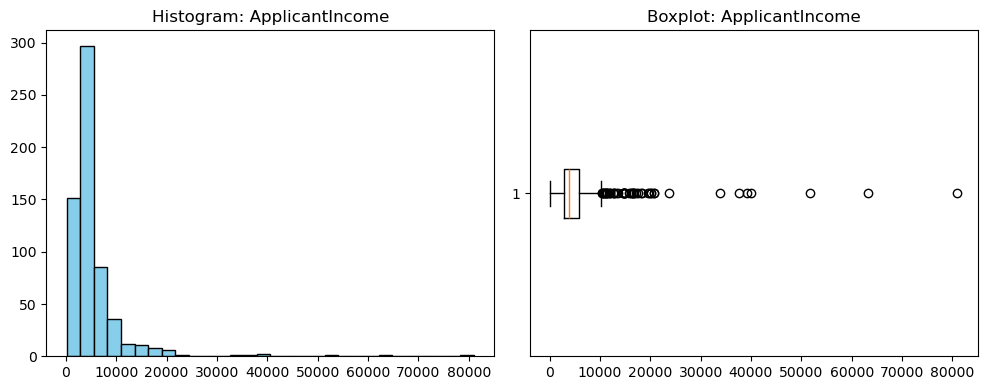

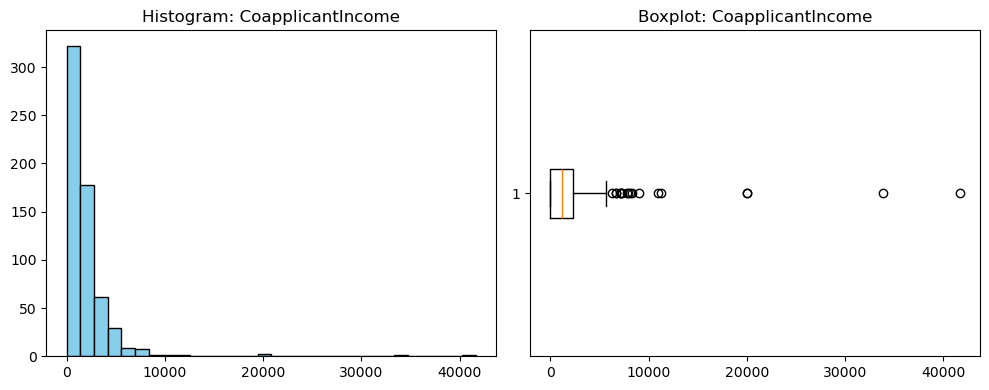

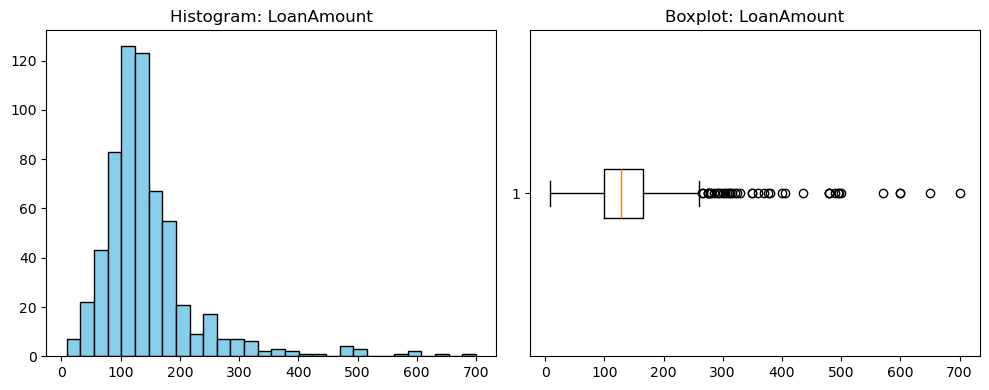

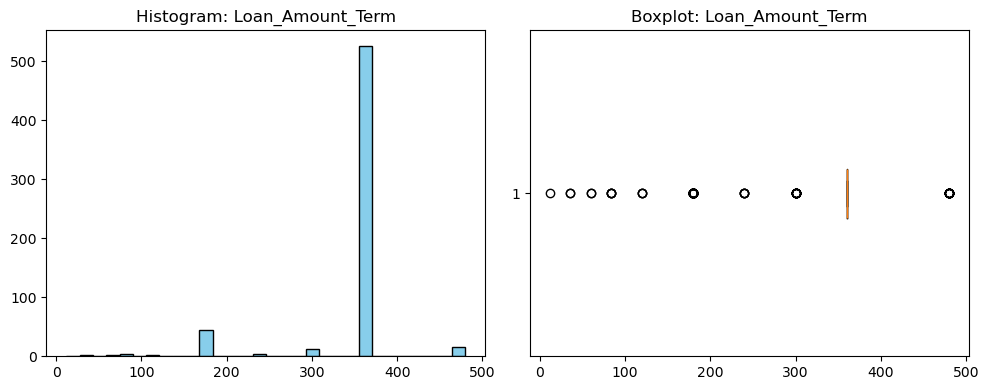

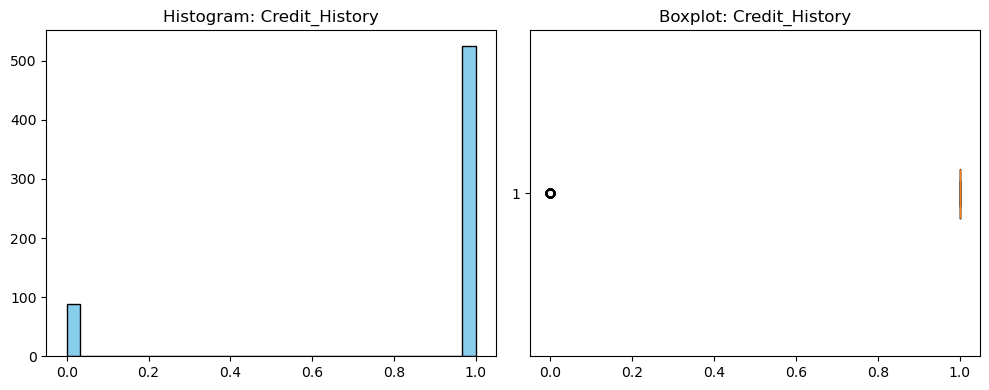

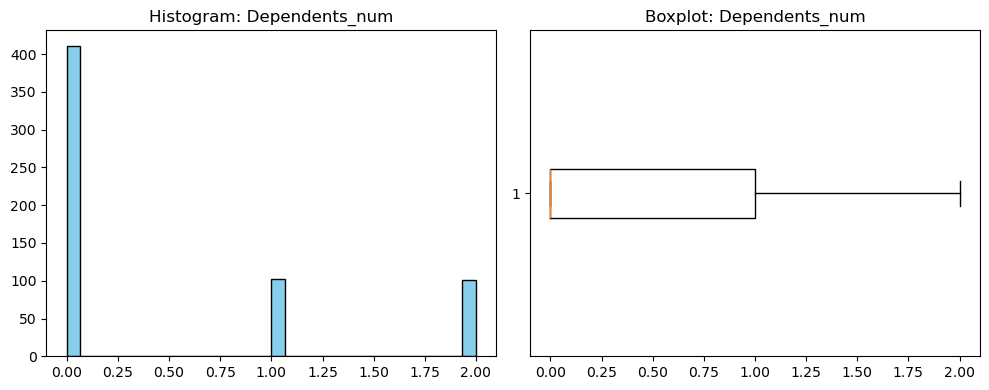

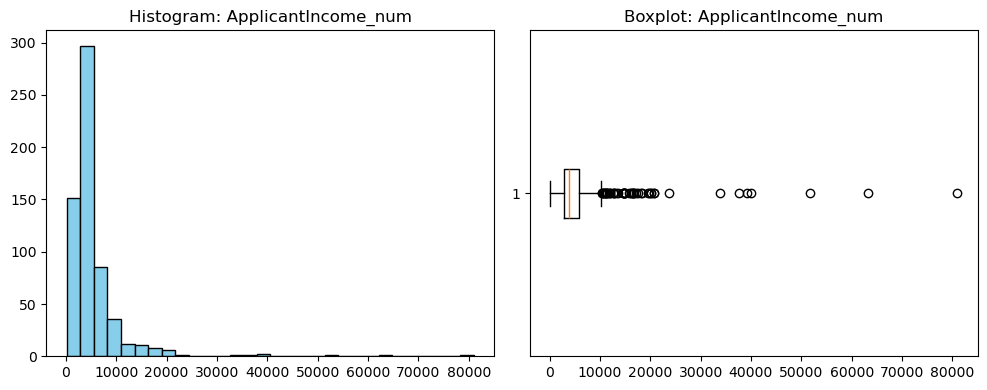

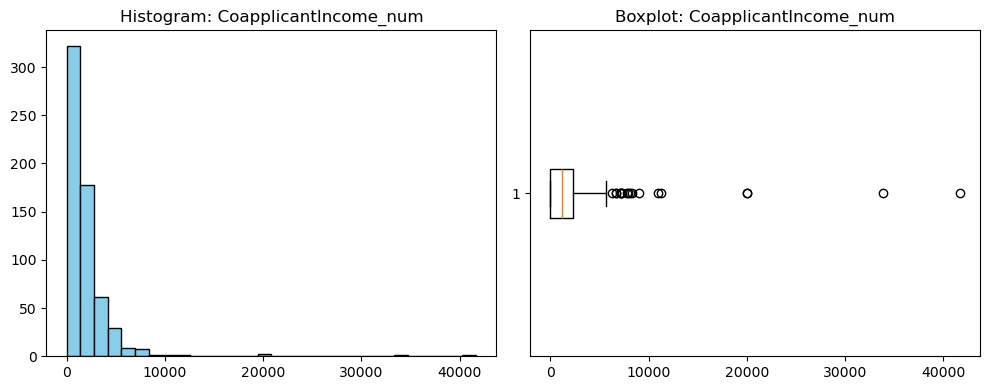

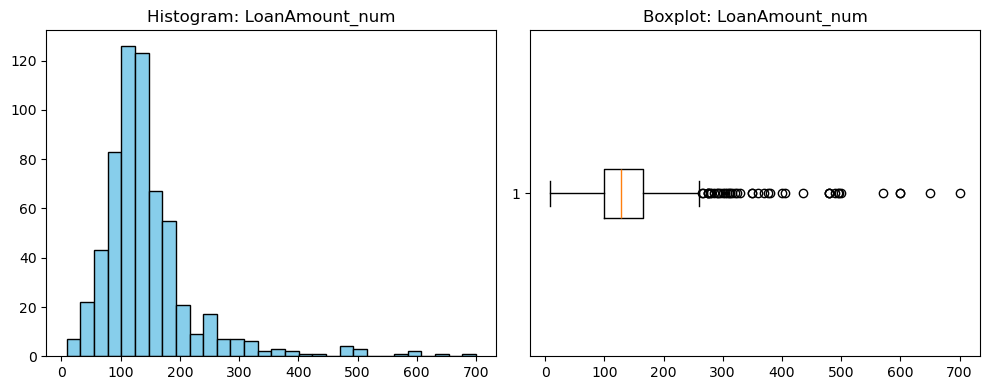

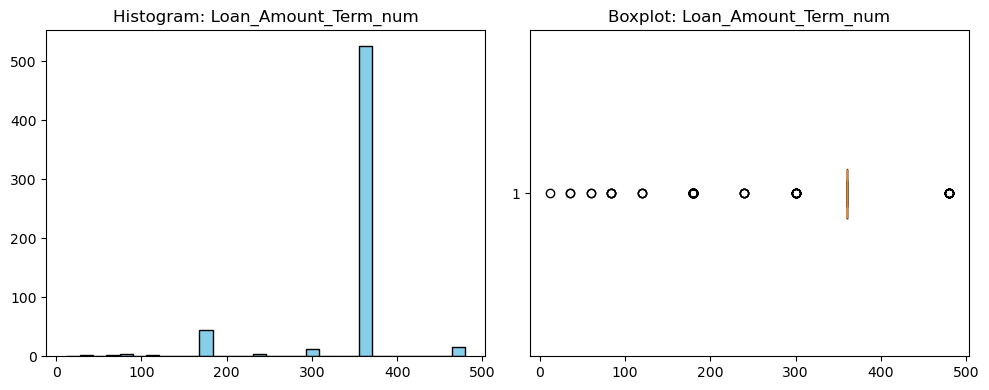

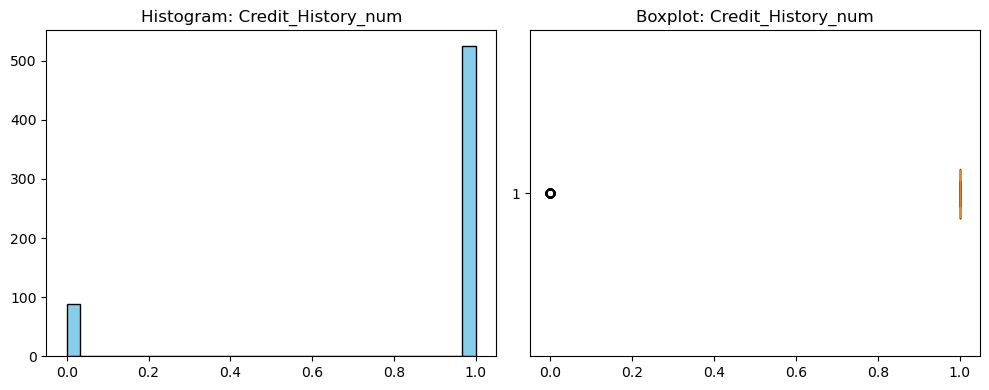

In [19]:
for c in numeric_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    
    ax[0].hist(df[c], bins=30, color='skyblue', edgecolor='black')
    ax[0].set_title(f'Histogram: {c}')
    
    ax[1].boxplot(df[c].dropna(), vert=False)
    ax[1].set_title(f'Boxplot: {c}')
    
    plt.tight_layout()
    plt.show()

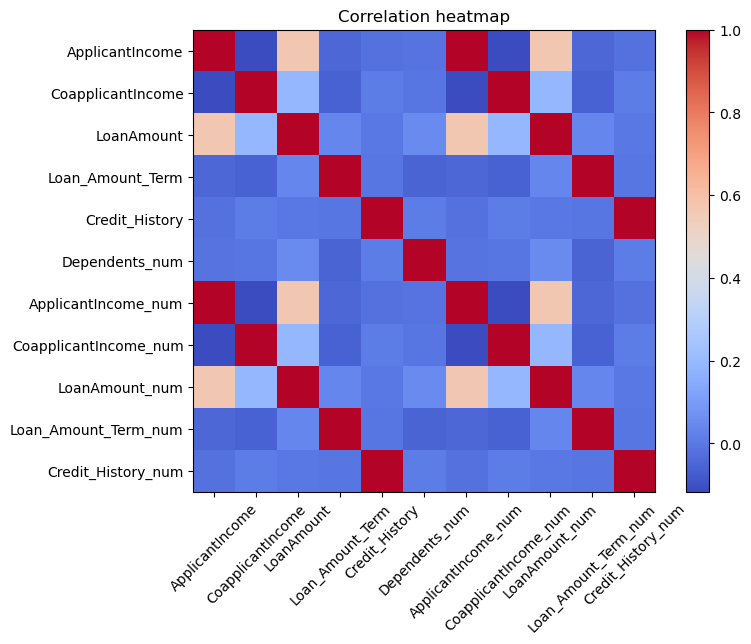

In [20]:
if len(numeric_cols) >= 2:
    corr = df[numeric_cols].corr()
    plt.figure(figsize=(8,6))
    plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
    plt.colorbar()
    plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=45)
    plt.yticks(range(len(numeric_cols)), numeric_cols)
    plt.title('Correlation heatmap')
    plt.show()
    corr

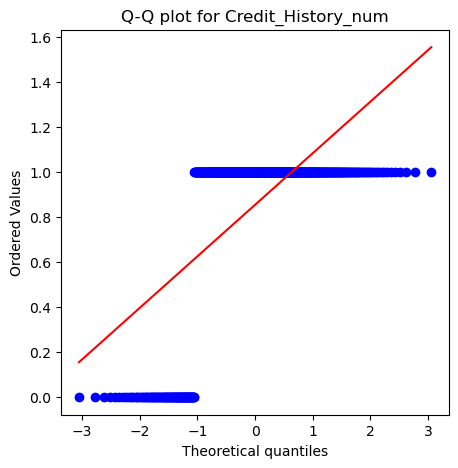

In [21]:
plt.figure(figsize=(5,5))
stats.probplot(df[target], dist='norm', plot=plt)
plt.title(f'Q-Q plot for {target}')
plt.show()

In [22]:
n = len(df[target])
mean = df[target].mean()
se = stats.sem(df[target])
ci = stats.t.interval(0.95, df=n-1, loc=mean, scale=se) if n > 1 else (mean, mean)
print('95% CI for mean:', ci)

pop_value = mean * 0.9
t_stat, p_val = stats.ttest_1samp(df[target], pop_value)
print(f'H0: mean({target}) = {pop_value:.4f}')
print('t-statistic:', t_stat, 'p-value:', p_val)

95% CI for mean: (np.float64(0.8271245488524878), np.float64(0.8829731710172192))
H0: mean(Credit_History_num) = 0.7695
t-statistic: 6.013327893899565 p-value: 3.123570176753652e-09


MSE: 0.13100154748936368 RMSE: 0.3619413591859373 R2: -0.0029971720478656483


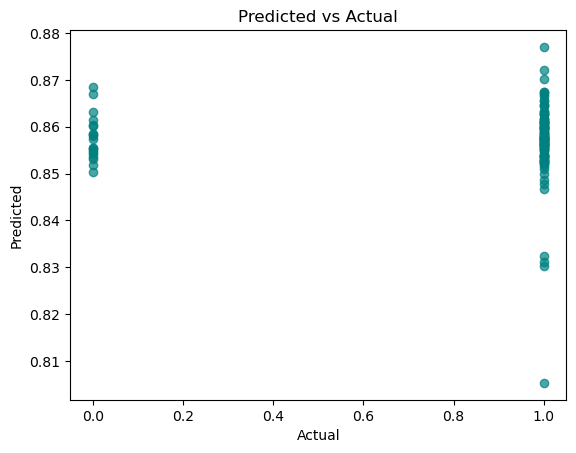

In [23]:
if len(predictors) >= 1:
    X = df[predictors].values
    y = df[target].values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    print('MSE:', mse, 'RMSE:', rmse, 'R2:', r2)

    plt.scatter(y_test, preds, alpha=0.7, color='teal')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title('Predicted vs Actual')
    plt.show()
else:
    print('Not enough numeric predictors for regression.')

In [24]:
df.to_csv('cleaned_dataset.csv', index=False)
print('✅ Saved cleaned dataset to cleaned_dataset.csv')

✅ Saved cleaned dataset to cleaned_dataset.csv
